# Chapitre 16 - Cours 2 : apprendre un ensemble, puis le post-traiter

Ce second notebook couvre la section 16.3 du livre. L'idée, due à Friedman et
Popescu, est de **séparer** les deux tâches de l'apprentissage ensembliste :

1. construire un dictionnaire **fini** de fonctions de base (des arbres) à partir des
   données ;
2. les **combiner** en ajustant un chemin de lasso dans ce dictionnaire.

Nous verrons le post-traitement d'une forêt aléatoire sur les données spam
(figure 16.6), l'algorithme ISLE de génération d'ensembles (algorithme 16.2,
figure 16.8) et les **ensembles de règles** (RuleFit simplifié, figure 16.10).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl.ch16_ensembles import (standardize, lasso_path_cd, lasso_path_fast,
                                isle_ensemble, tree_predictions,
                                staged_ensemble_predictions, extract_rules,
                                rule_matrix, rule_to_str)

## 1. Le modèle et le post-traitement lasso

On considère des fonctions de la forme (éq. (16.8) du livre)
$$
f(x)=\alpha_0+\sum_{T_k\in\mathcal T}\alpha_k\,T_k(x),
$$
où $\mathcal T$ est un dictionnaire de fonctions de base, typiquement des arbres. Le
cours 1 a montré que le gradient boosting avec rétrécissement suit un chemin
régularisé $L_1$ monotone dans l'espace de **tous** les arbres. Friedman et Popescu
proposent une approche hybride en deux étapes :

- induire à partir des données un dictionnaire fini
  $\mathcal T_L=\{T_1(x),\dots,T_M(x)\}$ ;
- ajuster un chemin de lasso dans ce dictionnaire (éq. (16.9)) :
$$
\alpha(\lambda)=\arg\min_\alpha\ \sum_{i=1}^N L\Big[y_i,\ \alpha_0+\sum_{m=1}^M\alpha_mT_m(x_i)\Big]+\lambda\sum_{m=1}^M|\alpha_m|.
$$

> **Intuition.** Dans sa forme la plus simple, c'est un **post-traitement** d'une forêt
> aléatoire ou d'un modèle boosté : au lieu de faire la moyenne (ou la somme) de
> *tous* les arbres avec des poids fixés, on ré-estime leurs poids par un lasso. Le
> lasso en annule beaucoup : le modèle final est plus petit (moins de calculs et de
> stockage pour prédire), et souvent au moins aussi précis.

Concrètement : on calcule la matrice $N\times M$ des prédictions $T_m(x_i)$ de chaque
arbre sur l'échantillon d'apprentissage, puis on la traite comme une matrice de
prédicteurs ordinaire pour le lasso. Nous utilisons la perte quadratique
$L(y,f)=(y-f)^2$, y compris en classification (réponse codée 0/1, on prédit la
classe 1 si $\hat f(x)>1/2$).

## 2. Post-traitement d'une forêt aléatoire sur les données spam (figure 16.6)

Les données spam (4601 courriels, 57 prédicteurs) n'ont pas de découpage
apprentissage/test fourni ici ; nous tirons au hasard 1536 courriels de test, comme
dans le livre.

In [2]:
spam = datasets.load_spam()
Xs_all = spam.drop(columns="spam").to_numpy(float)
ys_all = spam["spam"].to_numpy(int)
rng = np.random.RandomState(0)
perm = rng.permutation(len(ys_all))
te, tr = perm[:1536], perm[1536:]
Xs, ys, Xs_te, ys_te = Xs_all[tr], ys_all[tr], Xs_all[te], ys_all[te]
print("apprentissage :", Xs.shape, " test :", Xs_te.shape)

apprentissage : (3065, 57)  test : (1536, 57)


**La forêt aléatoire.** 500 arbres de profondeur maximale, $m=7$ variables candidates
à chaque coupure (algorithme 15.1). Les forêts aléatoires ont été programmées au
chapitre 15 ; nous utilisons ici celles de scikit-learn pour la rapidité.

In [3]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=500, max_features=7, random_state=0, n_jobs=4)
rf.fit(Xs, ys)
err_rf = np.mean(rf.predict(Xs_te) != ys_te)
print("erreur test de la forêt (500 arbres) : %.4f" % err_rf)

erreur test de la forêt (500 arbres) : 0.0482


Matrice des prédictions de chaque arbre (probabilité de spam, ici 0 ou 1 pour des
arbres développés jusqu'au bout) sur l'apprentissage et sur le test.

In [4]:
T_rf = np.column_stack([e.predict_proba(Xs)[:, 1] for e in rf.estimators_])
T_rf_te = np.column_stack([e.predict_proba(Xs_te)[:, 1] for e in rf.estimators_])
print(T_rf.shape, T_rf_te.shape)

(3065, 500) (1536, 500)


Chemin du lasso (notre descente de coordonnées `lasso_path_cd`), puis erreur test le
long du chemin, en fonction du **nombre d'arbres retenus** (coefficients non nuls).

In [5]:
def path_test_error(b0, coefs, T_test, y_test):
    """Taux d'erreur test le long d'un chemin de post-traitement (réponse 0/1)."""
    pred = b0[:, None] + coefs @ T_test.T
    return np.mean((pred > 0.5) != y_test[None, :], axis=1)


lam_rf, b0_rf, coef_rf = lasso_path_cd(T_rf, ys, n_lambdas=40, lambda_ratio=1e-3, tol=1e-5)
nz_rf = (coef_rf != 0).sum(axis=1)
err_post_rf = path_test_error(b0_rf, coef_rf, T_rf_te, ys_te)
print("nombre d'arbres retenus :", nz_rf[::5])

nombre d'arbres retenus : [  0  38  79 111 123 131 132 169]


**Une forêt « décorrélée ».** Variante du livre : chaque arbre est construit sur un
sous-échantillon *sans remise* de 5 % des données et limité à 6 feuilles. Les arbres
sont alors bien plus différents les uns des autres - et bien plus rapides à
construire. On l'obtient avec `isle_ensemble` en prenant $\eta=0{,}05$, $\nu=0$
(des arbres indépendants, voir le paragraphe 3) et 7 variables candidates par coupure.

In [6]:
f0_s, trees_s = isle_ensemble(Xs, ys, n_trees=500, eta=0.05, nu=0.0, max_leaf_nodes=6,
                              max_features=7, rng=np.random.RandomState(0))
T_s = tree_predictions(trees_s, Xs)
T_s_te = tree_predictions(trees_s, Xs_te)
err_rf5 = np.mean((f0_s + T_s_te.mean(axis=1) > 0.5) != ys_te)
print("erreur test de la moyenne des 500 petits arbres : %.4f" % err_rf5)

erreur test de la moyenne des 500 petits arbres : 0.1022


In [7]:
lam_s, b0_s, coef_s = lasso_path_cd(T_s, ys, n_lambdas=40, lambda_ratio=1e-3, tol=1e-5)
nz_s = (coef_s != 0).sum(axis=1)
err_post_s = path_test_error(b0_s, coef_s, T_s_te, ys_te)

Pour référence, un gradient boosting à arbres de 5 feuilles (chapitre 10 ; version
scikit-learn, déviance binomiale).

In [8]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=300, max_leaf_nodes=5, learning_rate=0.1,
                                random_state=0).fit(Xs, ys)
err_gb = np.mean(gb.predict(Xs_te) != ys_te)
print("erreur test du gradient boosting : %.4f" % err_gb)

erreur test du gradient boosting : 0.0547


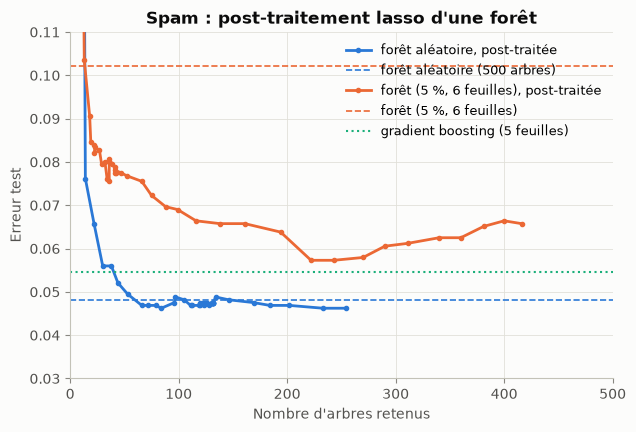

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(nz_rf, err_post_rf, "o-", ms=3, color=BLUE, label="forêt aléatoire, post-traitée")
ax.axhline(err_rf, color=BLUE, ls="--", lw=1.2, label="forêt aléatoire (500 arbres)")
ax.plot(nz_s, err_post_s, "o-", ms=3, color=ORANGE, label="forêt (5 %, 6 feuilles), post-traitée")
ax.axhline(err_rf5, color=ORANGE, ls="--", lw=1.2, label="forêt (5 %, 6 feuilles)")
ax.axhline(err_gb, color=COLORS[2], ls=":", lw=1.5, label="gradient boosting (5 feuilles)")
ax.set(title="Spam : post-traitement lasso d'une forêt", xlabel="Nombre d'arbres retenus",
       ylabel="Erreur test", ylim=(0.03, 0.11), xlim=(0, 500))
ax.legend()
plt.show()

Comme dans le livre : le post-traitement de la forêt usuelle apporte une amélioration
modeste mais atteint l'erreur de la forêt complète avec **moins d'une centaine
d'arbres** au lieu de 500. Pour la forêt
« décorrélée » de petits arbres, le gain du post-traitement est beaucoup plus net
(la moyenne simple de ces arbres est médiocre), pour un coût de calcul très réduit,
même si le résultat reste un peu en retrait.

In [10]:
for k in (20, 40, 80):
    i = np.argmin(np.abs(nz_rf - k))
    print("forêt post-traitée avec %3d arbres : erreur test %.4f" % (nz_rf[i], err_post_rf[i]))

forêt post-traitée avec  22 arbres : erreur test 0.0658
forêt post-traitée avec  38 arbres : erreur test 0.0560
forêt post-traitée avec  79 arbres : erreur test 0.0469


> **Remarque.** Nous montrons ici le chemin entier sur l'échantillon test pour
> visualiser l'effet du post-traitement. En pratique, $\lambda$ doit être choisi sur des
> données indépendantes (validation croisée ou échantillon de validation).

## 3. Construire un bon ensemble : l'algorithme ISLE

Tous les ensembles ne se prêtent pas bien au post-traitement. Il faut des fonctions de
base qui (i) couvrent bien l'espace là où c'est utile et (ii) soient suffisamment
**différentes** les unes des autres.

Friedman et Popescu s'inspirent de l'**intégration numérique**. On écrit la fonction
inconnue comme une intégrale (éq. (16.10))
$$
f(x)=\int\beta(\gamma)\,b(x;\gamma)\,d\gamma ,
$$
où $\gamma\in\Gamma$ paramètre les fonctions de base (pour un arbre : variables de
coupure, seuils, valeurs des feuilles).

Une **méthode de quadrature** choisit $M$ points $\gamma_m$ et des poids $\alpha_m$ tels que
$f_M(x)=\alpha_0+\sum_m\alpha_m\,b(x;\gamma_m)$ approche bien $f$. L'**échantillonnage
préférentiel** (importance sampling) tire les $\gamma_m$ au hasard, mais en favorisant
les régions pertinentes de $\Gamma$. Pour mesurer le (manque de) pertinence d'une
fonction de base, on utilise (éq. (16.11))
$$
Q(\gamma)=\min_{c_0,c_1}\sum_{i=1}^N L\big(y_i,\,c_0+c_1\,b(x_i;\gamma)\big):
$$
c'est l'erreur de la meilleure fonction affine de la seule base $b(\cdot;\gamma)$. La
meilleure base unique est $\gamma^*=\arg\min_\gamma Q(\gamma)$.

Introduire du hasard dans le choix de $\gamma$ donne nécessairement
$Q(\gamma)\ge Q(\gamma^*)$ ; la **largeur** du schéma d'échantillonnage $\mathcal S$ est
(éq. (16.12))
$$
\sigma=\mathbb E_{\mathcal S}\big[Q(\gamma)-Q(\gamma^*)\big].
$$
- $\sigma$ trop petit : les $b(x;\gamma_m)$ se ressemblent toutes (et ressemblent à
  $b(x;\gamma^*)$) ;
- $\sigma$ trop grand : les bases sont très variées, mais beaucoup sont inutiles.

**Algorithme 16.2 (génération d'un ensemble ISLE).**

1. $f_0(x)=\arg\min_c\sum_{i=1}^NL(y_i,c)$.
2. Pour $m=1,\dots,M$ :
   - (a) $\gamma_m=\arg\min_\gamma\sum_{i\in S_m(\eta)}L\big(y_i,\,f_{m-1}(x_i)+b(x_i;\gamma)\big)$ ;
   - (b) $f_m(x)=f_{m-1}(x)+\nu\,b(x;\gamma_m)$.
3. $\mathcal T_{ISLE}=\{b(x;\gamma_1),\dots,b(x;\gamma_M)\}$.

Ici $S_m(\eta)$ est un sous-échantillon de taille $N\eta$ tiré **sans remise**
($0<\eta\le1$) : diminuer $\eta$ augmente le hasard, donc la largeur $\sigma$. Le
paramètre $\nu\in[0,1]$ introduit une **mémoire** : plus $\nu$ est grand, plus on évite
des bases semblables à celles déjà trouvées (on ajuste le résidu).

Pour la perte quadratique, l'étape (a) consiste à ajuster un arbre aux résidus
$y_i-f_{m-1}(x_i)$ sur $S_m$ ; c'est ce que fait `isle_ensemble`. Cas particuliers :

| schéma | $\eta$ | $\nu$ |
|---|---|---|
| bagging | 1, avec remise | 0 |
| forêt aléatoire | idem + tirage des variables de coupure | 0 |
| gradient boosting avec rétrécissement | 1 | $>0$ |
| gradient boosting stochastique | $<1$ | $>0$ |

Friedman et Hall montrent que tirer sans remise la moitié des données
($\eta=1/2$) équivaut à peu près au bootstrap, en plus économique. Les auteurs
recommandent $\nu=0{,}1$ et $\eta\le 1/2$ (et $\eta\sim1/\sqrt N$ pour $N$ grand) ;
l'ensemble « génération ISLE + post-traitement lasso » s'appelle *Importance
Sampled Learning Ensemble*.

### Une simulation de régression (éq. (16.13))

La fonction cible est
$$
f(X)=10\cdot\prod_{j=1}^5e^{-2X_j^2}+\sum_{j=6}^{35}X_j,
$$
avec $X\sim\mathcal U[0,1]^{100}$ (les 65 dernières variables sont du bruit), et
$Y=f(X)+\varepsilon$, $\varepsilon\sim\mathcal N(0,1{,}3^2)$, ce qui donne un rapport
signal/bruit d'environ 2. On prend $N=1000$ et on mesure
$\mathbb E(\hat f(X)-f(X))^2$ sur 2000 points test (erreur par rapport à la **vraie**
fonction).

In [11]:
def f_true(X):
    return 10 * np.exp(-2 * (X[:, :5] ** 2).sum(axis=1)) + X[:, 5:35].sum(axis=1)


def simulate(n, rng):
    X = rng.rand(n, 100)
    return X, f_true(X) + 1.3 * rng.randn(n)


rng = np.random.RandomState(0)
Xr, yr = simulate(1000, rng)
Xr_te = rng.rand(2000, 100)
fr_te = f_true(Xr_te)
print("rapport signal/bruit Var(f)/sigma^2 = %.2f" % (f_true(Xr).var() / 1.3 ** 2))

rapport signal/bruit Var(f)/sigma^2 = 1.96


**Largeur $\sigma$ en fonction de $\eta$.** Avant de comparer les modèles, illustrons
la notion de largeur : pour des arbres à 6 feuilles ajustés à $y$ ($\nu=0$) sur des
sous-échantillons de taille $N\eta$, calculons $Q(\gamma_m)$ (régression linéaire
simple de $y$ sur la base $b(\cdot;\gamma_m)$) et comparons à l'arbre construit sur
toutes les données, proxy de $\gamma^*$.

In [12]:
def Q(b, y):
    """Somme des carrés résiduels de la régression de y sur (1, b)."""
    A = np.column_stack([np.ones_like(b), b])
    coef = np.linalg.lstsq(A, y, rcond=None)[0]
    return np.sum((y - A @ coef) ** 2)


_, tree_star = isle_ensemble(Xr, yr, n_trees=1, eta=1.0, nu=0.0, max_leaf_nodes=6)
Q_star = Q(tree_star[0].predict(Xr), yr)
etas = [0.5, 0.2, 0.1, 0.05, 0.02]
widths, mean_corr = [], []
for eta in etas:
    _, tr_eta = isle_ensemble(Xr, yr, n_trees=60, eta=eta, nu=0.0, max_leaf_nodes=6,
                              rng=np.random.RandomState(1))
    B = tree_predictions(tr_eta, Xr)
    widths.append(np.mean([Q(B[:, m], yr) for m in range(B.shape[1])]) - Q_star)
    C = np.corrcoef(B.T)
    mean_corr.append(C[np.triu_indices_from(C, 1)].mean())
print("Q(gamma*) = %.0f" % Q_star)

Q(gamma*) = 4346


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(etas, widths, "o-", color=BLUE)
axes[0].set(xscale="log", title=r"Largeur $\sigma=E[Q(\gamma)-Q(\gamma^*)]$",
            xlabel=r"fraction sous-échantillonnée $\eta$", ylabel=r"$\sigma$")
axes[1].plot(etas, mean_corr, "o-", color=ORANGE)
axes[1].set(xscale="log", title="Corrélation moyenne entre deux arbres",
            xlabel=r"fraction sous-échantillonnée $\eta$", ylabel="corrélation")
for ax in axes:
    ax.set_xticks(etas, [str(e).replace(".", ",") for e in etas])
    ax.minorticks_off()
plt.show()

Plus $\eta$ est petit, plus les arbres sont individuellement médiocres ($\sigma$ grand)
mais différents les uns des autres (faible corrélation) : c'est le compromis que
l'importance sampling cherche à régler.